# Bowers 型振幅・周波数ランプによる単一モード光学MSゲート

Bowers et al., [arXiv:2511.14364](https://arxiv.org/pdf/2511.14364), Fig. 1, Eqs. (3), (4), End Matter と Supplement Eq. (5) に基づく。実験では磁場勾配とマイクロ波による有効力が $g(t)=\Omega_g(t)J_2(4\Omega_\mu(t)/\delta_\mu)$ に比例し、モード周波数を変えて $\Delta=\omega_m-\omega_g-2\delta_\mu$ を掃引する。

**このノートの対応付け**：光学モデルでは同じ時間依存の力を $S_x$ に、離調を有効位相 $\Phi=\int\Delta dt$ に入力する。2つの同一アームの間の理想エコーをトグリング描像で第2アームの力の符号反転として扱う。物理的な回転パルスの時間・誤差、実験の初期・終端の基底回転、磁場駆動の他の高調波は含めない。散逸は従来の光学MSモデル（単一モード、有限LD補正、固定の公称散逸率）。出力は理想 $\exp(+i\pi XX/4)$ に対する平均ゲート不忠実度・生成子である。

**基準波形**：論文の $\tau_m=50\,\mu$s 条件を選び、片腕527 µs、勾配10 µs、マイクロ波30 µs、離調掃引50 µs、残り347 µsを保持とする。端点のAWGスプラインを再現するためのノットは指定されていないため、逆離調の中央を直線、両端を滑らかな接続とした。論文の全ゲートは1055 µs、本モデルの力の2アームは1054 µs。この527 µsのアームを基に全体を100 µsにスケーリングし、同じゲート時間で公称矩形・較正済み矩形・較正済みランプを比較する。

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import jv
from scipy.linalg import logm
from IPython.display import display

import ms_gate_functions as mg
import noise_error_structure as ns
import smooth_detuning_analysis as controls
import drive_calibration_qpt_analysis as qpt
from drive_amplitude_calibration import amplitude_update_from_hxx
from laser_pulse_optimization import ms_magnus_metrics

durations_us = (100.,)
occupations = (0.01, 1., 2., 3., 4.)
points = 20001  # odd, includes the echo boundary
workers = 4
angle_tolerance = 2e-3
output_dir = Path("results/bowers_ramped_ms")
target = np.pi / 4

## 波形と数値診断

4項Blackman–Harris窓の片側を0–1に正規化して各駆動の立上りに使用する。周波数掃引の両端各10%の丸め幅は本モデルの選択。正の離調を用い、全区間を同率で圧縮し、離調を逆比で拡大する。公称ピーク結合は1次LDのMagnus角で設定し、後段のQPTで温度ごとに再較正する。表示する終端変位 $|\alpha(T)|$ は理想線形力での診断値。

In [17]:
def blackman_harris_rise(x):
    u = np.pi * np.clip(x, 0., 1.)
    a, b, c, d = 0.35875, 0.48829, 0.14128, 0.01168
    window = a - b*np.cos(u) + c*np.cos(2*u) - d*np.cos(3*u)
    return (window - (a-b+c-d)) / (2*(b+d))

def reciprocal_progress(x, edge=0.1):
    # Quadratic caps join the linear reciprocal-detuning sweep with C1 continuity.
    x = np.clip(x, 0., 1.)
    integral = np.where(x < edge, x*x/(2*edge),
                        np.where(x > 1-edge, 1-edge-(1-x)**2/(2*edge), x-edge/2))
    return integral / (1-edge)

def make_controls(duration_us):
    time = np.linspace(0., duration_us*1e-6, points)
    compression = 1054. / duration_us
    ref_us = time * 1e6 * compression
    arm_time = np.mod(ref_us, 527.)
    edge_time = np.minimum(arm_time, 527.-arm_time)
    gradient = blackman_harris_rise(edge_time / 10.)
    microwave = blackman_harris_rise((edge_time-10.) / 30.)
    force = gradient*jv(2, 2.405*microwave)/jv(2, 2.405)
    force *= np.where(ref_us < 527., 1., -1.)
    progress = reciprocal_progress((edge_time-40.)/50.)
    delta = 2*np.pi*compression / ((1-progress)/153500. + progress/15000.)
    trial = force * (2*np.pi*1e3*compression)
    angle = ms_magnus_metrics(time, trial, delta)["xx_angle"]
    if angle <= 0:
        raise ValueError("Check detuning sign and target convention")
    ramp = {"time_s":time, "A_rad_s":trial*np.sqrt(target/angle), "delta_rad_s":delta}
    T = time[-1]
    rect_config = controls.StandardGateConfigSI(gate_time_s=T, detuning_hz=1/T,
                                                 effective_sideband_hz=1/(4*T))
    rect = controls.build_standard_pulse_si(rect_config, points)
    return rect_config, {"rect":rect, "ramp":ramp}

for duration in durations_us:
    _, pulses = make_controls(duration)
    ramp = pulses["ramp"]
    time, A, delta = (ramp[k] for k in ("time_s", "A_rad_s", "delta_rad_s"))
    diag = ms_magnus_metrics(time, A, delta)
    print(f"{duration:g} µs: XX angle={diag['xx_angle']:.6g}, "
          f"|alpha(T)|={diag['displacement_abs']:.3g}, "
          f"max |dΔ/dt|/Δ²={np.max(abs(np.gradient(delta,time))/delta**2):.3g}")
    fig, axes = plt.subplots(2, 1, sharex=True, constrained_layout=True)
    axes[0].plot(time*1e6, A/(2*np.pi*1e3))
    axes[1].plot(time*1e6, delta/(2*np.pi*1e3))
    axes[0].set_ylabel("Signed A / 2π (kHz)")
    axes[1].set(xlabel="Time (µs)", ylabel="Δ / 2π (kHz)")
    plt.show()

100 µs: XX angle=0.785398, |alpha(T)|=0.0319, max |dΔ/dt|/Δ²=0.213


## QPTと振幅較正

同一時間・同一温度で公称矩形、振幅較正後の矩形、Bowers型ランプの振幅較正後を比較する。各温度で両波形に同一のフォノン次元を用いる。全ノイズON、光散乱率一定。各振幅でCPTP射影後の符号付き $h_{XX}$ を評価する。時間格子・フォノン次元の収束は別途確認する。

計算を開始・再開する場合は関数定義後に明示的に run_comparison() を呼ぶ。完了済みの結果は末尾のセル単独でCSVから読み込める。

In [ ]:
import fcntl
import hashlib
import json
import os
try:
    from tqdm.auto import tqdm
except ImportError:
    class tqdm:
        """Plain-text progress bar for kernels without tqdm."""
        def __init__(self, *, total, desc, unit):
            self.total, self.desc, self.unit = total, desc, unit
            self.done, self.status = 0, ""

        def __enter__(self):
            return self

        def __exit__(self, exc_type, exc, traceback):
            print(flush=True)

        def set_postfix_str(self, status, refresh=True):
            self.status = status
            if refresh:
                self.show()

        def update(self, n=1):
            self.done += n
            self.show()

        def show(self):
            filled = 20 * self.done // max(1, self.total)
            bar = "#" * filled + "-" * (20 - filled)
            print(f"\r{self.desc}: [{bar}] {self.done}/{self.total} {self.unit}  {self.status}   ",
                  end="", flush=True)


def evaluate(nbar, scale, pulse, cfg, rect_cfg, dim):
    dt = pulse["time_s"][1]
    params = controls._qpt_parameters(pulse, dt, cfg, rect_cfg)
    params.update(A=scale*pulse["A_rad_s"], phonon_dim_override=dim)
    chi = qpt.calculate_error_channel_batch((nbar,), params, convention="undo_before_actual")[0]["chi"]
    return chi

def analyze_channel(chi):
    channel, projected, _ = qpt.project_trace_normalized_chi_to_cptp(chi)
    generator = logm(mg.superoperator_to_ptm(channel))
    if np.linalg.norm(generator.imag) > 1e-8:
        raise ValueError("Error generator has a significant imaginary part")
    terms = ns._decompose_generator_taxonomy(generator.real)
    coeff = pd.Series(terms["coefficients"], index=[f"{s}:{m}" for s,m in terms["metadata"]])
    return coeff, 80*(1-projected[0,0].real)


def matches_reference(reference, entry, identity, pulse):
    """Compare scalar settings and sampled controls at round-off precision."""
    if entry is None:
        return False
    saved, wave, _ = entry
    if saved.keys() != identity.keys():
        return False
    for key, value in identity.items():
        a, b = np.asarray(saved[key]), np.asarray(value)
        if a.shape != b.shape:
            return False
        if a.dtype.kind == "f" or b.dtype.kind == "f":
            if not np.allclose(a, b, rtol=1e-12, atol=0):
                return False
        elif not np.array_equal(a, b):
            return False
    for key in ("A_rad_s", "delta_rad_s", "time_s"):
        a, b = reference[f"{wave}_{key}"], pulse[key]
        if a.shape != b.shape or not np.allclose(a, b, rtol=1e-12,
                                                 atol=1e-13 * np.max(np.abs(a))):
            return False
    return True

def run_comparison():
    output_dir.mkdir(parents=True, exist_ok=True)
    with (output_dir / ".sweep.lock").open("a+") as lock:
        try:
            fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError:
            raise RuntimeError("This output directory already has an active sweep.")
        with tqdm(total=3*len(durations_us)*len(occupations), desc="Completed conditions",
                  unit="condition") as progress:
            with np.load(Path("results/bowers_ramped_ms/reference_controls_v1.npz"), allow_pickle=False) as reference:
                return resume_sweep(progress, reference)

def resume_sweep(progress, reference):
    manifest = json.loads(str(reference["manifest"]))
    rows, vectors = [], {}
    for duration in durations_us:
        rect_cfg, pulses = make_controls(duration)
        for nbar in occupations:
            cfg = controls.NbarSweepConfig(nbar_values=(nbar,), parallel_workers=workers, show_progress=True)
            excursion = max(2*np.max(abs(p["A_rad_s"]))/np.min(abs(p["delta_rad_s"])) for p in pulses.values())
            dim = mg.estimate_phonon_dim(nbar, 1.15*excursion)
            for name, pulse in pulses.items():
                prefix = f"T{duration:g}_n{nbar:g}_{name}"
                labels = ["nominal", "calibrated"] if name == "rect" else ["calibrated"]
                scale = 1.
                previous = None
                params = controls._qpt_parameters(pulse, pulse["time_s"][1], cfg, rect_cfg)
                identity = {k:v for k,v in params.items() if k not in
                            ("A","delta","parallel_workers","show_progress")}
                identity.update(dim=dim, tolerance=angle_tolerance, target=target)
                digest = hashlib.sha256(json.dumps(identity, sort_keys=True).encode())
                for field in ("A_rad_s","delta_rad_s","time_s"):
                    digest.update(pulse[field].tobytes())
                entry = manifest.get(prefix)
                signature = (entry[2] if matches_reference(reference, entry, identity, pulse)
                             else digest.hexdigest())
                for label in labels:
                    condition = name+"_"+label
                    path = output_dir / f"{prefix}_{label}.npz"
                    progress.set_postfix_str(path.stem, refresh=True)
                    if path.exists():
                        with np.load(path, allow_pickle=False) as cache:
                            chi = cache["chi"]
                            if "signature" in cache:
                                if str(cache["signature"]) != signature:
                                    raise ValueError(f"Different simulation settings for {path}; use a separate output_dir")
                            elif legacy_cache.get(path.name) != (hashlib.sha256(path.read_bytes()).hexdigest(), signature):
                                raise ValueError(f"Unrecognized legacy cache: {path}")
                            scale = float(cache["scale"]) if "scale" in cache else (1. if label=="nominal" else np.nan)
                        if chi.shape != (16,16) or not np.isfinite(chi).all() or not np.isclose(chi.trace(),1.):
                            raise ValueError(f"Invalid channel: {path}")
                        coeff, infidelity = analyze_channel(chi)
                    else:
                        for iteration in range(6):
                            if previous is not None:
                                chi, coeff, infidelity = previous
                                previous = None
                            else:
                                progress.set_postfix_str(f"{path.stem}  evaluation {iteration+1}")
                                chi = evaluate(nbar, scale, pulse, cfg, rect_cfg, dim)
                                coeff, infidelity = analyze_channel(chi)
                            if label == "nominal" or abs(coeff["H:XX"]) <= angle_tolerance:
                                break
                            scale = amplitude_update_from_hxx(scale, coeff["H:XX"])
                        else:
                            raise RuntimeError(f"Calibration failed for {path}")
                        tmp = path.with_suffix(".tmp.npz")
                        np.savez_compressed(tmp, chi=chi, scale=scale, signature=signature)
                        os.replace(tmp, path)
                    if label=="calibrated" and abs(coeff["H:XX"]) > angle_tolerance:
                        raise ValueError(f"Cached calibration outside tolerance: {path}")
                    if label=="nominal":
                        previous = (chi, coeff, infidelity)
                    vectors[(duration,nbar,condition)] = coeff
                    rows.append(dict(T_us=duration,n_bar=nbar,condition=condition,hxx=coeff["H:XX"],
                                     infidelity_percent=infidelity, scale=scale, phonon_dim=dim,
                                     peak_kHz=scale*np.max(abs(pulse["A_rad_s"]))/(2*np.pi*1000)))
                    progress.update()
    summary = pd.DataFrame(rows)
    coefficients = pd.concat(vectors, names=["T_us","n_bar","condition","term"]).rename("coefficient")
    summary.to_csv(output_dir/"summary.csv", index=False)
    coefficients.to_csv(output_dir/"hsca.csv")
    return summary, coefficients

# Verified chi-only checkpoints from the original notebook run.
legacy_cache = {'T100_n0.01_ramp_calibrated.npz': ('eb0f031fd87701f226e22eb05383d67d803dd6b153fc7da4adaf6f7c6435741a',
                                    '2fa0a3aef5d607d423222f0e96ef936b6721a5b254cf007356d2a32005e6fd3d'),
 'T100_n0.01_rect_calibrated.npz': ('547988adba7c457e5a527373d4e156b19b70a1347c552b4317a8537568847a6d',
                                    '70f4e2a1b5225819eac90d79264ad61d90aff3795b59240f5c0fd103980c14b0'),
 'T100_n0.01_rect_nominal.npz': ('64f8374b3bf2f7c6aa344b410e49f6984616f8c0f0a02140887c3bf3696fb538', '70f4e2a1b5225819eac90d79264ad61d90aff3795b59240f5c0fd103980c14b0'),
 'T100_n1_ramp_calibrated.npz': ('0b936184f1ef4ec072f9fd19e9d3d263ae467a79739ba10139bdbcf296b67602', '71f6e40dbf0c3582001dc43fc3a546f68da5e6c3fe0959af7809a5c5257465f1'),
 'T100_n1_rect_calibrated.npz': ('8f78f7c3d56dfabbc37f0c61e0c3f2c46a15fb1d649902a178d39ea0e974997e', '7efb77197254743c4d6615c649b3037887649f928d1d67db1baaf119c34e9b25'),
 'T100_n1_rect_nominal.npz': ('c7c5a3812bca31449e3a86d500efd1299deed036b28308b000d2825461ca0b6f', '7efb77197254743c4d6615c649b3037887649f928d1d67db1baaf119c34e9b25'),
 'T100_n2_ramp_calibrated.npz': ('aba5994650e810433e1177e0460ad80886594bf79d06d782577f237ac3a132f9', '7be29e1a90bb7c91f10bfd8d86dbf9ed8f1534b37badfe90e882e2692b52561c'),
 'T100_n2_rect_calibrated.npz': ('cc5ecda9e8e506e21de1e13409f2a916413c2e00b617baa8d28ee1bd1de611d1', '03b9421db5b5cc644b9f17c085350a83fc86352b663e323fc0e730d77d66583a'),
 'T100_n2_rect_nominal.npz': ('a1dbd44e9b7ef824c0119ba8f24ceff9061ed52c08022ba8ca2d926ca1fbeb3c', '03b9421db5b5cc644b9f17c085350a83fc86352b663e323fc0e730d77d66583a'),
 'T100_n3_rect_nominal.npz': ('4a66e800ee2ace7c79d6da6b58918e347f6160361b145c03e19434e8ece752d8', '145a99f7d614e32893798d7f18d8f5b8abe61934df8ffd230729b3e3a9a52830')}

# Invoke run_comparison() explicitly to start or resume a simulation.
# The results cell below reads the completed sweep without acquiring its lock.

## 不忠実度と生成子成分

温度ごとの不忠実度、および各時間の平均フォノン数4での変化量・残留量上位5成分を表示する。指定の3成分は全温度で同条件の較正済み矩形を基準に比較する。正の低減率は係数の絶対値が減少したことを示す。

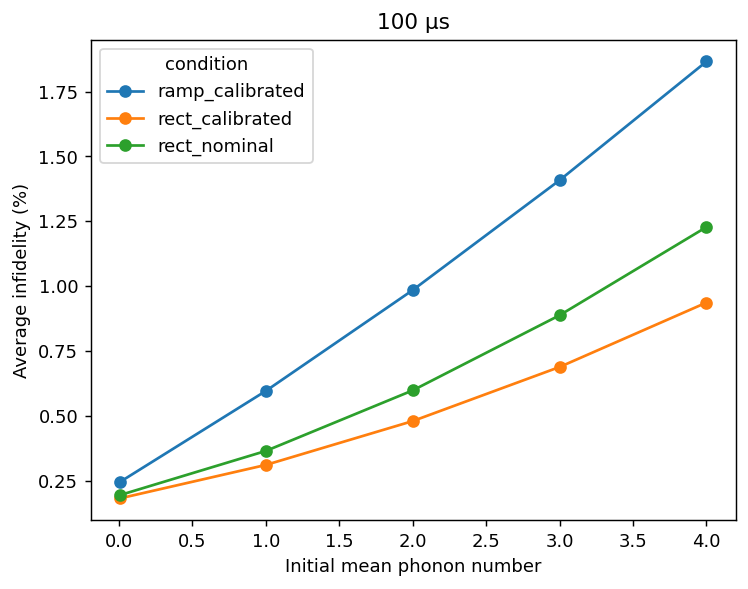

condition,rect_calibrated,ramp_calibrated,change
term,,,
S:XI,0.002820,0.008966,0.006147
"C:IX,XI",0.002795,0.008941,0.006147
S:IX,0.002820,0.008966,0.006146
H:XX,0.000434,-0.000151,-0.000586
S:XX,0.005191,0.004939,-0.000252


condition,ramp_calibrated
term,
S:XI,0.008966
S:IX,0.008966
"C:IX,XI",0.008941
S:XX,0.004939
S:XY,0.000208


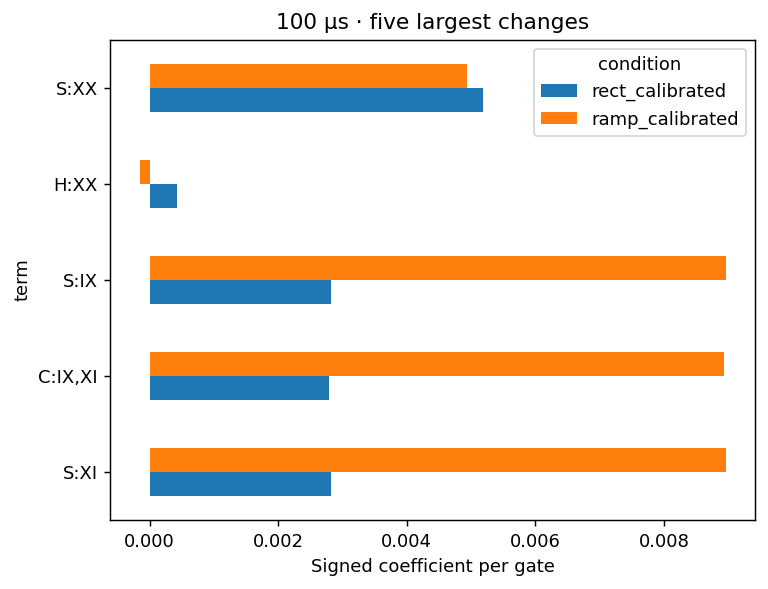

condition            rect_calibrated  ramp_calibrated  reduction_percent
T_us  n_bar term                                                        
100.0 0.01  S:XI            0.000562         0.001046         -86.112658
            S:IX            0.000562         0.001047         -86.226424
            C:IX,XI         0.000537         0.001021         -90.185940
      1.00  S:XI            0.001123         0.003011        -168.164417
            S:IX            0.001123         0.003011        -168.169323
            C:IX,XI         0.001098         0.002986        -172.000024
      2.00  S:XI            0.001689         0.004995        -195.804315
            S:IX            0.001689         0.004995        -195.815941
            C:IX,XI         0.001664         0.004970        -198.752935
      3.00  S:XI            0.002254         0.006980        -209.723795
            S:IX            0.002254         0.006980        -209.720941
            C:IX,XI         0.002229         0.006955        -212.075711
      4.00  S:XI            0.002820         0.008966        -218.011472
            S:IX            0.002820         0.008966        -217.992494
            C:IX,XI         0.002795         0.008941        -219.953736

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# Read the saved results of the completed 100 µs run (no QPT or lock).
results_dir = Path("results/bowers_ramped_ms")
summary = pd.read_csv(results_dir / "summary.csv")
coefficients = pd.read_csv(results_dir / "hsca.csv").set_index(
    ["T_us", "n_bar", "condition", "term"]
)["coefficient"].sort_index()
durations_shown = sorted(summary.T_us.unique())
occupations_shown = sorted(summary.n_bar.unique())

selected = ["S:XI", "S:IX", "C:IX,XI"]
comparisons = []
for duration in durations_shown:
    sweep = summary.loc[summary.T_us == duration]
    sweep.pivot(index="n_bar", columns="condition", values="infidelity_percent").plot(
        marker="o", xlabel="Initial mean phonon number", ylabel="Average infidelity (%)",
        title=f"{duration:g} µs")
    plt.show()
    for nbar in occupations_shown:
        table = coefficients.loc[(duration,nbar)].unstack("condition")
        delta = table["ramp_calibrated"] - table["rect_calibrated"]
        comparison = table.loc[selected, ["rect_calibrated","ramp_calibrated"]].copy()
        comparison["reduction_percent"] = 100*(1-comparison.ramp_calibrated.abs() /
                                               comparison.rect_calibrated.abs().replace(0,np.nan))
        comparisons.append(comparison.assign(T_us=duration, n_bar=nbar))
        if nbar == 4:
            changed = delta.abs().nlargest(5).index
            remaining = table.ramp_calibrated.abs().nlargest(5).index
            print(f"{duration:g} µs, nbar=4: signed changes and signed ramp residuals")
            display(table.loc[changed, ["rect_calibrated","ramp_calibrated"]].assign(change=delta.loc[changed]))
            display(table.loc[remaining, ["ramp_calibrated"]])
            table.loc[changed, ["rect_calibrated","ramp_calibrated"]].plot.barh(
                xlabel="Signed coefficient per gate", title=f"{duration:g} µs · five largest changes")
            plt.show()
display(pd.concat(comparisons).reset_index().set_index(["T_us","n_bar","term"]))